# Wu et al. 2020 — AML · 02 · Cell-state manifold / trajectory

Match the scFates method to the topology. First fit a **tree** to inspect fork biology (is there a Gast/pSom co-expression hub diverging into opposing arms?). Finding no fork, fit a fold-free **curve**, root at the Gast/pSom-high developmental origin, compute pseudotime, and verify continuity off an **independent** diffmap embedding.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

**Load `processed.h5ad`; re-score modules and graph-smooth for geography.**

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
cc = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
u,s,vt = np.linalg.svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 96881 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.37
Gast: 41/81 genes present
pSom: 47/98 genes present
Crest: 72/104 genes present
raw module means (honest readout): {'Gast': 0.0019, 'pSom': 0.0066, 'Crest': -0.0042}


**Smoothed spatial correlations.** Strong Gast↔pSom anti-correlation with Crest opposing Gast and co-varying weakly with pSom — one axis, organized cross-repression, Crest a terminal readout.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].mean())
sub = adata   # whole manifold is the trajectory object (no proliferation lobe to scope out)

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.68
  Crest_sm vs Gast_sm: r = -0.67
  Crest_sm vs pSom_sm: r = +0.11
cycling fraction: 0.001 (single low-cycling body)


**Topology, step 1 — fit a tree and inspect the fork biology.** If the manifold branched, a fork would separate a Gast-leaning from a pSom-leaning arm. No fork appears; both tips are pSom-high / Crest-low.

In [5]:
ad_t = sub.copy(); sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100, ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect biology:')
for grp,node in [('tip%d'%t,t) for t in tips_t] + [('fork%d'%f,f) for f in forks_t]:
    m = np.isin(hard_t, np.where(Dt[node]<=2)[0])
    print(f'  {grp}: n={int(m.sum()):6d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).')

tree: 3 tips, 1 fork(s) -> inspect biology:
  tip2: n= 10441 Gast=+0.0038 pSom=+0.0053 Crest=-0.0053
  tip13: n= 28843 Gast=+0.0026 pSom=+0.0067 Crest=-0.0052
  tip15: n= 30911 Gast=+0.0024 pSom=+0.0064 Crest=-0.0038
  fork19: n= 16030 Gast=+0.0037 pSom=+0.0054 Crest=-0.0053
no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).


**Topology, step 2 — fit a fold-free curve.** Sweep node count and check the fold self-approach ratio (min graph-distant node separation / median edge length; >1 = no fold). Stable and fold-free.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.90
curve N=30: 2 tips, 0 forks | self-approach 2.41
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.90 (>1 = fold-free)


**Root at the developmental origin.** Score each tip by Gast+pSom−Crest; root at the argmax (Gast/pSom EARLY, Crest LATE). Pseudotime then rises into the Crest-high terminus, and is not proliferation-driven (near-zero correlation with cycling score).

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
for m,l in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{l}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m); rho_c,_ = spearmanr(t, cyc)
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (cell-cycle-free axis)')

tip 0: Gast=+0.0025 pSom=+0.0067 Crest=-0.0051
tip 2: Gast=+0.0023 pSom=+0.0064 Crest=-0.0036
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.057 p=1.5e-71
  pSom_sm: rho=-0.025 p=6.3e-15
  Crest_sm: rho=+0.433 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.82
Somitogenesis-high decile mean pseudotime = 0.45
Gastrulation-high decile mean pseudotime = 0.47
caveat: pseudotime vs cycling score rho = -0.07 (cell-cycle-free axis)


**Continuity on an independent embedding.** Diffusion components are computed independently of the UMAP being judged; pseudotime tracking DC1 (|r|≥0.8) certifies one continuous gradient, immune to a UMAP fold.

In [8]:
sc.tl.diffmap(sub)
r_dc1 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,2])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} (>=0.8 on a component = continuous)')
assert max(r_dc1, r_dc2) > 0.8, 'continuity check failed on independent embedding'

|corr(pseudotime, DC1)| = 0.91 | DC2 = 0.04 (>=0.8 on a component = continuous)


**Confirm the house orientation is pseudotime-consistent** (root on the left) and re-use `X_umap_lin` from step 01 — never re-embed a linear compartment.

In [9]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f} (root on left)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97 (root on left)


**Save `manifold.h5ad` + deliverable `manifold.pdf`** (pseudotime on the house linear layout).

saved manifold.h5ad + manifold.pdf


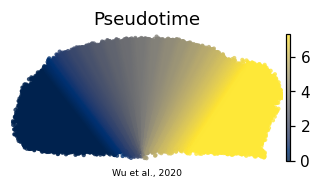

In [10]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')